# Batch processing of Sentinel-2 images

This notebook processes a time series of Level-1 images (Sentinel-2 L1C `.SAFE`, or Landsat
Collection 2 L1) of one or several tiles into GRS Level-2A products:

1. **Configuration**: input/output folders, tiles, date range, auxiliary data, processing options.
2. **List the Level-1 images** found on disk, with their cloud cover, and select a date range.
3. **Auxiliary data and output naming**: CAMS file of the month, optional DEM of the tile, and one
   L2A product per image, named as with the `grs` command line.
4. **Run the batch**: images already processed are skipped, too cloudy images or images without CAMS
   data are skipped, a failing image is logged and does not stop the batch, and a summary table is saved.
5. **Quick look** at one L2A product.

Each image is processed with {py:class}`grs.Process <grs.grs_process.Process>` as in the
{doc}`Sentinel-2 tutorial <../processing>`. For very long batches (hundreds of full tiles), the command
line is more robust than a notebook: each image runs in its own Python process, so memory is fully
released between images, and several images can be processed in parallel (see the last section).

A full Sentinel-2 tile at 20 m needs about 10 GB of memory. In a notebook, start Jupyter with the
environment variable `MALLOC_ARENA_MAX=2` (already set by the `grs` command and in the Docker images):
the memory freed by the processing threads is then reused from one image to the next, which saves 2 to
3 GB.

In [1]:
import os
import gc
import re
import glob
import time
import shutil
import logging
import warnings
import datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import grs
from grs.run import set_ofile

opj = os.path.join

# INFO messages of the processing chain; set to logging.WARNING for a quieter batch
logging.getLogger().setLevel(logging.INFO)
# deprecation notices of the dependencies, not useful here
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='Consolidated metadata')
warnings.filterwarnings('ignore', message='Significant no-data areas detected')   # OmniCloudMask, swath edge
warnings.filterwarnings('ignore', message='Dataset has no geotransform')

print(f'grs: {grs.__version__}')

grs: 3.1.0


## 1. Configuration

The Level-1 images are expected in a `<idir>/<tile>/YYYY/MM/DD/<image>` tree; the L2A products are
written to the same tree under `<odir>/<tile>`.

| Parameter | Description |
|---|---|
| `idir`, `odir` | root folders of the Level-1 inputs and of the L2A outputs |
| `tiles` | tile sub-folders to process (e.g. `30TWT`, or a Landsat path/row `199027`) |
| `pattern` | glob pattern of the Level-1 image names (`'S2*.SAFE'`, `'L*_L1*'` for Landsat) |
| `start_date`, `end_date` | date range to process (inclusive) |
| `cams_file_template` | CAMS file of the month of the acquisition, formatted with the image `date` (see the {doc}`CAMS tutorial <../auxdata>`) |
| `dem_file_template` | DEM GeoTIFF subset to the tile, formatted with `tile`; `None` or missing file: no DEM (fine over the sea) |
| `resolution` | pixel size (m) of the L2A product (10, 20 or 60 for Sentinel-2, 30 for Landsat) |
| `aot_resolution` | pixel size (m) of the coarse grid of the aerosol retrieval, multiple of `resolution` |
| `max_cloud_cover` | skip the images whose Level-1 cloud cover (0-1) is greater or equal |
| `opac_model`, `scale_aot` | force the aerosol model (`None`: from CAMS), scaling factor of the CAMS AOD |
| `out_ext` | `'.zarr'` (Zarr store with overviews) or `'.nc'` (NetCDF, plus a `_anc.nc` ancillary file) |
| `levname`, `suffix` | level name and suffix of the output name (`None`: `_V<grs version>`), as `--levname` / `--suffix` of the command line |
| `overwrite` | reprocess images whose L2A output already exists |

In [2]:
idir = '/data/satellite/Sentinel-2/L1C'
odir = '/data/satellite/Sentinel-2/L2A_zarr'
tiles = ['31TEJ']
pattern = 'S2*.SAFE'
start_date, end_date = '2025-08-01', '2025-08-31'

# other example (Landsat, path/row sub-folders):
# idir, odir, tiles, pattern = '/data/satellite/landsat/L1', '/data/satellite/landsat/L2A', ['199027'], 'L*_L1*'

cams_file_template = '/data/cams/world/cams_forecast_{date:%Y-%m}.nc'
dem_file_template = '/home/harmel/Dropbox/Dropbox/satellite/dem/COP-DEM_GLO-30-DGED_{tile}.tif'   # or None

resolution = 20        # m
aot_resolution = 480   # m, multiple of resolution
max_cloud_cover = 0.6  # 0-1
opac_model = None      # e.g. 'DESE_rh70' to force desert dust
scale_aot = 1

out_ext = '.zarr'      # '.zarr' or '.nc'
levname = 'L2AGRS'
suffix = None          # None: '_V<grs version>'
overwrite = False

## 2. List the Level-1 images

The images are indexed by their acquisition date, taken from the `YYYY/MM/DD` folders, so that a date
range can be selected with `.loc`. The cloud cover is read from the Level-1 metadata
(`MTD_MSIL1C.xml` for Sentinel-2, `*_MTL.txt` for Landsat); it is `NaN` when it cannot be found.

In [3]:
def cloud_cover(path):
    """Level-1 cloud cover (0-1) from the image metadata, NaN if not found."""
    patterns = [('MTD_MSIL1C.xml', r'<Cloud_Coverage_Assessment>\s*([\d.]+)'),
                ('*_MTL.txt', r'\bCLOUD_COVER\s*=\s*"?([\d.]+)')]
    for metadata, regex in patterns:
        for file in glob.glob(opj(path, metadata)):
            with open(file) as f:
                match = re.search(regex, f.read())
            if match:
                return float(match.group(1)) / 100
    return np.nan


def list_images(idir, tiles, pattern='S2*.SAFE'):
    """Table of the Level-1 images found in <idir>/<tile>/YYYY/MM/DD/, indexed by acquisition date."""
    rows = []
    for tile in tiles:
        for path in sorted(glob.glob(opj(idir, tile, '*', '*', '*', pattern))):
            year, month, day = Path(path).parts[-4:-1]
            rows.append(dict(date=pd.Timestamp(f'{year}-{month}-{day}'), tile=tile,
                             name=os.path.basename(path.rstrip('/')), path=path))
    df = pd.DataFrame(rows, columns=['date', 'tile', 'name', 'path'])
    df['cloud_cover'] = df['path'].map(cloud_cover)
    return df.set_index('date').sort_index()


images = list_images(idir, tiles, pattern)
print(f'{len(images)} Level-1 images found in {idir} for tiles {tiles}')
images.head()

548 Level-1 images found in /data/satellite/Sentinel-2/L1C for tiles ['31TEJ']


,tile,name,path,cloud_cover
date,,,,
2019-01-30,31TEJ,S2A_MSIL1C_20190130T103251_N0500_R108_T31TEJ_2...,/data/satellite/Sentinel-2/L1C/31TEJ/2019/01/3...,0.000000
2019-05-13,31TEJ,S2A_MSIL1C_20190513T104031_N0500_R008_T31TEJ_2...,/data/satellite/Sentinel-2/L1C/31TEJ/2019/05/1...,0.006657
2019-06-12,31TEJ,S2A_MSIL1C_20190612T104031_N0500_R008_T31TEJ_2...,/data/satellite/Sentinel-2/L1C/31TEJ/2019/06/1...,0.091898
2019-06-29,31TEJ,S2A_MSIL1C_20190629T103031_N0500_R108_T31TEJ_2...,/data/satellite/Sentinel-2/L1C/31TEJ/2019/06/2...,0.000000
2019-07-02,31TEJ,S2A_MSIL1C_20190702T104031_N0500_R008_T31TEJ_2...,/data/satellite/Sentinel-2/L1C/31TEJ/2019/07/0...,0.116125


In [4]:
selection = images.loc[start_date:end_date]
print(f'{len(selection)} images between {start_date} and {end_date}')
selection.groupby([selection.tile, selection.index.year]).size().rename('images per year').unstack(fill_value=0)

21 images between 2025-08-01 and 2025-08-31


date,2025
tile,
31TEJ,21


## 3. Auxiliary data and output naming

For each image:

- the **CAMS file** is the one of the month of the acquisition; images without CAMS file are skipped
  (see the {doc}`CAMS tutorial <../auxdata>` to download it);
- the **DEM** is the GeoTIFF of the tile, if it exists;
- the **L2A product** is named as with the `grs` command line (`grs.run.set_ofile`): level name of
  the image replaced by `levname`, plus `suffix`, e.g.
  `S2B_MSIL2AGRS_20200411T110619_N0500_R137_T30TWT_20230509T002033_V3.1.0`. It is written in a folder
  of that name under `<odir>/<tile>/YYYY/MM/DD/`, with the per-image log file `log_file.log`.

In [5]:
def dem_file(tile):
    if dem_file_template is None:
        return None
    file = dem_file_template.format(tile=tile)
    return file if os.path.exists(file) else None


def l2a_path(row, date):
    """Output product: <odir>/<tile>/YYYY/MM/DD/<name>/<name><out_ext>, as with the command line."""
    outdir = set_ofile(row['name'], odir=opj(odir, row['tile'], date.strftime('%Y/%m/%d')),
                       level_name=levname, suffix=suffix if suffix is not None else f'_V{grs.__version__}')
    return str(outdir / (outdir.name + out_ext))


selection = selection.assign(
    cams_file=[cams_file_template.format(date=date) for date in selection.index],
    dem_file=selection['tile'].map(dem_file),
    l2a=[l2a_path(row, date) for date, row in selection.iterrows()])
selection['cams_ok'] = selection['cams_file'].map(os.path.exists)
selection['cloudy'] = selection['cloud_cover'] >= max_cloud_cover
selection['done'] = selection['l2a'].map(os.path.exists)

todo = ~selection['done'] & selection['cams_ok'] & ~selection['cloudy']
print(f"{selection['done'].sum()} already processed, {selection['cloudy'].sum()} too cloudy, "
      f"{(~selection['cams_ok']).sum()} without CAMS file, {todo.sum()} to process")
selection[['name', 'cloud_cover', 'cams_ok', 'dem_file', 'done']]

0 already processed, 0 too cloudy, 0 without CAMS file, 21 to process


,name,cloud_cover,cams_ok,dem_file,done
date,,,,,
2025-08-01,S2A_MSIL1C_20250801T104041_N0511_R008_T31TEJ_2...,0.352517,True,/home/harmel/Dropbox/Dropbox/satellite/dem/COP...,False
2025-08-01,S2B_MSIL1C_20250801T102559_N0511_R108_T31TEJ_2...,0.162438,True,/home/harmel/Dropbox/Dropbox/satellite/dem/COP...,False
2025-08-02,S2C_MSIL1C_20250802T105051_N0511_R051_T31TEJ_2...,0.082500,True,/home/harmel/Dropbox/Dropbox/satellite/dem/COP...,False
2025-08-04,S2A_MSIL1C_20250804T104701_N0511_R051_T31TEJ_2...,0.014217,True,/home/harmel/Dropbox/Dropbox/satellite/dem/COP...,False
2025-08-06,S2C_MSIL1C_20250806T102621_N0511_R108_T31TEJ_2...,0.558869,True,/home/harmel/Dropbox/Dropbox/satellite/dem/COP...,False
2025-08-07,S2B_MSIL1C_20250807T104619_N0511_R051_T31TEJ_2...,0.000000,True,/home/harmel/Dropbox/Dropbox/satellite/dem/COP...,False
2025-08-08,S2A_MSIL1C_20250808T102701_N0511_R108_T31TEJ_2...,0.000000,True,/home/harmel/Dropbox/Dropbox/satellite/dem/COP...,False
2025-08-11,S2A_MSIL1C_20250811T103701_N0511_R008_T31TEJ_2...,0.000000,True,/home/harmel/Dropbox/Dropbox/satellite/dem/COP...,False
2025-08-11,S2B_MSIL1C_20250811T102559_N0511_R108_T31TEJ_2...,0.000000,True,/home/harmel/Dropbox/Dropbox/satellite/dem/COP...,False


## 4. Run the batch

For each image:

- it is **skipped** if its L2A output already exists (unless `overwrite=True`), so the batch can be
  interrupted and restarted at any time; it is also skipped if it is too cloudy or has no CAMS file;
- {py:meth}`~grs.grs_process.Process.execute` sets up the processing (lazily, with dask) and
  {py:meth}`~grs.grs_process.Process.write_output` computes and writes the product, chunk by chunk;
- the processing messages are also written to `log_file.log` next to the product;
- if the processing **fails**, the error is logged, the partially written output (if any) is removed
  so that the image is retried at the next run, and the batch goes on.

In [6]:
def remove_output(path):
    """Remove an L2A product (Zarr store or NetCDF file with its ancillary file)."""
    for p in (path, path.replace('.nc', '_anc.nc') if path.endswith('.nc') else None):
        if p and os.path.isdir(p):
            shutil.rmtree(p)
        elif p and os.path.isfile(p):
            os.remove(p)


def process_image(row):
    """Process one image; return (status, duration in s, error message)."""
    if not row['cams_ok']:
        return 'no_cams', 0., f"missing {row['cams_file']}"
    if row['cloudy']:
        return 'cloudy', 0., ''
    l2a = row['l2a']
    if os.path.exists(l2a):
        if not overwrite:
            return 'skipped', 0., ''
        remove_output(l2a)
    os.makedirs(os.path.dirname(l2a), exist_ok=True)

    # copy of the processing messages in the product folder
    handler = logging.FileHandler(opj(os.path.dirname(l2a), 'log_file.log'))
    handler.setFormatter(logging.Formatter('%(asctime)s %(levelname)s %(message)s'))
    logging.getLogger().addHandler(handler)
    t0 = time.perf_counter()
    try:
        process = grs.Process()
        process.execute(row['path'], odir=l2a,
                        cams_file=row['cams_file'], dem_file=row['dem_file'],
                        resolution=resolution, aot_resolution=aot_resolution,
                        opac_model=opac_model, scale_aot=scale_aot)
        process.write_output()
        return 'done', time.perf_counter() - t0, ''
    except Exception as e:
        logging.exception(f"processing failed: {row['path']}")
        remove_output(l2a)
        return 'failed', time.perf_counter() - t0, f'{type(e).__name__}: {e}'
    finally:
        logging.getLogger().removeHandler(handler)
        handler.close()
        # release the memory of the image before the next one
        process = None
        gc.collect()


records = []
for i, (date, row) in enumerate(selection.iterrows(), start=1):
    status, duration, error = process_image(row)
    records.append(dict(date=date, tile=row['tile'], status=status, duration_s=round(duration, 1),
                        error=error, l1=row['path'], l2a=row['l2a']))
    print(f"[{i}/{len(selection)}] {status:7s} {row['name']} ({duration:.0f} s)")

summary = pd.DataFrame(records, columns=['date', 'tile', 'status', 'duration_s', 'error', 'l1', 'l2a'])
summary['status'].value_counts()

[1/21] done    S2A_MSIL1C_20250801T104041_N0511_R008_T31TEJ_20250801T131318.SAFE (241 s)
[2/21] done    S2B_MSIL1C_20250801T102559_N0511_R108_T31TEJ_20250801T140637.SAFE (148 s)
[3/21] done    S2C_MSIL1C_20250802T105051_N0511_R051_T31TEJ_20250802T142718.SAFE (137 s)
[4/21] done    S2A_MSIL1C_20250804T104701_N0511_R051_T31TEJ_20250804T132304.SAFE (136 s)
[5/21] done    S2C_MSIL1C_20250806T102621_N0511_R108_T31TEJ_20250806T124750.SAFE (136 s)
[6/21] done    S2B_MSIL1C_20250807T104619_N0511_R051_T31TEJ_20250807T112421.SAFE (127 s)
[7/21] done    S2A_MSIL1C_20250808T102701_N0511_R108_T31TEJ_20250808T130243.SAFE (133 s)
[8/21] done    S2A_MSIL1C_20250811T103701_N0511_R008_T31TEJ_20250811T155519.SAFE (236 s)
[9/21] done    S2B_MSIL1C_20250811T102559_N0511_R108_T31TEJ_20250811T124509.SAFE (150 s)
[10/21] done    S2C_MSIL1C_20250812T104641_N0511_R051_T31TEJ_20250812T142911.SAFE (128 s)
[11/21] done    S2A_MSIL1C_20250814T105041_N0511_R051_T31TEJ_20250814T133914.SAFE (146 s)
[12/21] done    S2B

status
done    21
Name: count, dtype: int64

The summary is saved as a CSV file in `odir`. Failed images can be inspected below (see also their
`log_file.log`) and reprocessed by running the batch again.

In [7]:
if len(summary):
    log_file = opj(odir, f'grs_batch_{dt.datetime.now():%Y%m%dT%H%M%S}.csv')
    os.makedirs(odir, exist_ok=True)
    summary.to_csv(log_file, index=False)
    print(f'summary saved to {log_file}')
    processed = summary[summary.status == 'done']
    if len(processed):
        print(f'mean processing time: {processed.duration_s.mean():.0f} s per image')

summary[summary.status.isin(['failed', 'no_cams'])][['date', 'tile', 'status', 'error', 'l1']]

summary saved to /data/satellite/Sentinel-2/L2A_zarr/grs_batch_20261016T093645.csv


,date,tile,status,error,l1


## 5. Quick look at one L2A product

The last available product of the selection is displayed: true-colour composite of the remote-sensing
reflectance $R_{rs}$ of the valid water pixels (`mask == 0`) and aerosol optical thickness retrieved
from the image (one value per block of `aot_chunk` = 256 coarse pixels, i.e. 123 km at `aot_resolution=480`: a single value for a whole Sentinel-2 tile; use e.g. `aot_resolution=240` or `120` for a spatially varying AOT). A Zarr product holds one group per resolution level (group `'0'`: full resolution)
and the ancillary data in group `'ancillary'`; see the {doc}`visualization tutorials <../visualization>` for more.

In [8]:
available = selection['l2a'][selection['l2a'].map(os.path.exists)]
if available.empty:
    raise FileNotFoundError('no L2A product available in the selection: check the summary above')
l2a_file = available.iloc[-1]
if l2a_file.endswith('.zarr'):
    l2a = xr.open_zarr(l2a_file, group='0')
else:
    l2a = xr.open_dataset(l2a_file, decode_coords='all')
l2a

<xarray.Dataset> Size: 4GB
Dimensions:             (y: 5490, x: 5490, wl: 11)
Coordinates:
  * y                   (y) float64 44kB 5.1e+06 5.1e+06 ... 4.99e+06 4.99e+06
  * x                   (x) float64 44kB 7e+05 7e+05 ... 8.097e+05 8.098e+05
  * wl                  (wl) int64 88B 443 490 560 665 705 ... 842 865 1610 2190
    central_wavelength  (wl) float32 44B dask.array<chunksize=(11,), meta=np.ndarray>
    band                int64 8B ...
    spatial_ref         int32 4B ...
    time                datetime64[ns] 8B ...
Data variables:
    aot550              (y, x) float64 241MB dask.array<chunksize=(256, 256), meta=np.ndarray>
    BRDFg               (y, x) float64 241MB dask.array<chunksize=(256, 256), meta=np.ndarray>
    dem                 (y, x) float64 241MB dask.array<chunksize=(256, 256), meta=np.ndarray>
    flags               (y, x) uint32 121MB dask.array<chunksize=(256, 256), meta=np.ndarray>
    mask                (y, x) uint8 30MB dask.array<chunksize=(256, 256), meta=np.ndarray>
    raa                 (y, x) float64 241MB dask.array<chunksize=(256, 256), meta=np.ndarray>
    Rrs                 (wl, y, x) float64 3GB dask.array<chunksize=(11, 256, 256), meta=np.ndarray>
    sza                 (y, x) float64 241MB dask.array<chunksize=(256, 256), meta=np.ndarray>
    vza                 (y, x) float64 241MB dask.array<chunksize=(256, 256), meta=np.ndarray>
    wind                (y, x) float64 241MB dask.array<chunksize=(1024, 1024), meta=np.ndarray>
Attributes: (12/77)
    long_name:                           CA BLUE GREEN RED VRE_1 VRE_2 VRE_3 ...
    constellation:                       Sentinel-2
    constellation_id:                    S2
    product_path:                        /data/satellite/Sentinel-2/L1C/32TQR...
    product_name:                        S2B_MSIL1C_20231224T101339_N0510_R02...
    instrument:                          MSI
    ...                                  ...
    hcld_threshold:                      0.003
    dirdata:                             /data/grs/grsdata
    abs_gas_file:                        /home/harmel/Dropbox/Dropbox/work/gi...
    water_vapor_transmittance_file:      /home/harmel/Dropbox/Dropbox/work/gi...
    GRSdriver_version:                   1.0.9
    metadata_profile:                    datacube

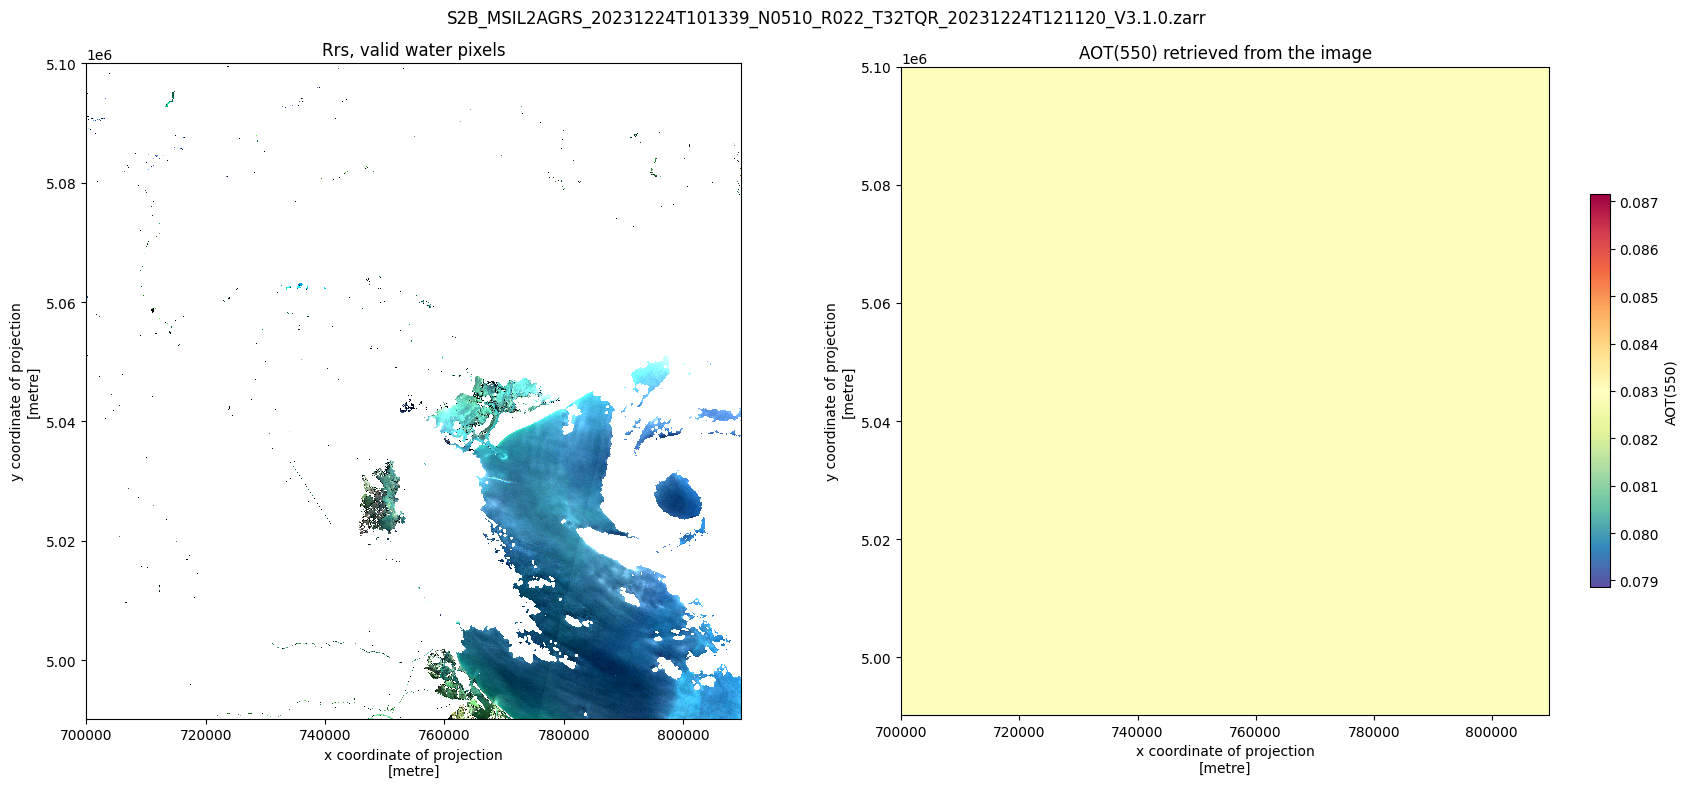

In [9]:
water = l2a.mask == 0

# maps in the UTM coordinates (m) of the product
fig, axs = plt.subplots(1, 2, figsize=(18, 8))
l2a.Rrs.sel(wl=[665, 560, 490], method='nearest').where(water).plot.imshow(
    rgb='wl', robust=True, ax=axs[0])
axs[0].set_title('Rrs, valid water pixels')
l2a.aot550.plot.imshow(ax=axs[1], cmap='Spectral_r', cbar_kwargs={'shrink': 0.6, 'label': 'AOT(550)'})
axs[1].set_title('AOT(550) retrieved from the image')
for ax in axs:
    ax.set_aspect('equal')
fig.suptitle(os.path.basename(l2a_file))
plt.tight_layout()

## Alternative: batch from the command line

For long batches, run one `grs` process per image (see {doc}`../../usage`): memory is fully released after each image, and
images can be processed in parallel. The cell below writes one `grs` command per image of the
selection (already processed images are skipped by `--no_clobber`, too cloudy ones by
`--max_cloud_cover`) to a text file, to be run from a shell.

In [10]:
commands = []
for date, row in selection[selection['cams_ok']].iterrows():
    cmd = (f"grs {row['path']} --cams_file {row['cams_file']} "
           f"--odir {opj(odir, row['tile'], date.strftime('%Y/%m/%d'))} "
           f"--resolution {resolution} --aot_resolution {aot_resolution} "
           f"--max_cloud_cover {max_cloud_cover} --scale_aot {scale_aot} --levname {levname} --no_clobber")
    if row['dem_file']:
        cmd += f" --dem_file {row['dem_file']}"
    if opac_model:
        cmd += f' --opac_model {opac_model}'
    if suffix is not None:
        cmd += f' --suffix {suffix}'
    commands.append(cmd)

command_file = opj(odir, 'grs_commands.txt')
os.makedirs(odir, exist_ok=True)
with open(command_file, 'w') as f:
    f.write('\n'.join(commands) + '\n')
print(f'{len(commands)} commands written to {command_file}\n')
print('\n'.join(commands[:3]))

21 commands written to /data/satellite/Sentinel-2/L2A_zarr/grs_commands.txt

grs /data/satellite/Sentinel-2/L1C/31TEJ/2025/08/01/S2A_MSIL1C_20250801T104041_N0511_R008_T31TEJ_20250801T131318.SAFE --cams_file /data/cams/world/cams_forecast_2025-08.nc --odir /data/satellite/Sentinel-2/L2A_zarr/31TEJ/2025/08/01 --resolution 20 --aot_resolution 480 --max_cloud_cover 0.6 --scale_aot 1 --levname L2AGRS --no_clobber --dem_file /home/harmel/Dropbox/Dropbox/satellite/dem/COP-DEM_GLO-30-DGED_31TEJ.tif
grs /data/satellite/Sentinel-2/L1C/31TEJ/2025/08/01/S2B_MSIL1C_20250801T102559_N0511_R108_T31TEJ_20250801T140637.SAFE --cams_file /data/cams/world/cams_forecast_2025-08.nc --odir /data/satellite/Sentinel-2/L2A_zarr/31TEJ/2025/08/01 --resolution 20 --aot_resolution 480 --max_cloud_cover 0.6 --scale_aot 1 --levname L2AGRS --no_clobber --dem_file /home/harmel/Dropbox/Dropbox/satellite/dem/COP-DEM_GLO-30-DGED_31TEJ.tif
grs /data/satellite/Sentinel-2/L1C/31TEJ/2025/08/02/S2C_MSIL1C_20250802T105051_N0511_

The commands can then be run one after the other, or several at a time (each full Sentinel-2 tile
needs several GB of memory, so keep the number of parallel jobs low):

```bash
# one after the other
bash /data/satellite/Sentinel-2/L2A_zarr/grs_commands.txt

# 2 images in parallel
xargs -P 2 -I{} bash -c '{}' < /data/satellite/Sentinel-2/L2A_zarr/grs_commands.txt
```

The command line writes the products with the same names as this notebook, but always as Zarr stores.